In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
# Set path
path = 'drive/MyDrive/Colab Notebooks/Structural Biology/data'

import os
if os.path.exists(path +'/figures') is False:
  os.mkdir(path +'/figures')

In [ ]:
!pip install biopython
!pip install scipy
!pip install matplotlib
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 74.6 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from Bio.PDB import PDBList, is_aa
from Bio.SVDSuperimposer import SVDSuperimposer
from Bio.PDB.PDBParser import PDBParser
import matplotlib.pyplot as plt

In [ ]:
def superimpose(segment_1, segment_2):
  """
  return the new coordinates of segment_2
  upon superposition with segment_1
  """
  sup = SVDSuperimposer()
  sup.set(segment_1, segment_2)
  sup.run()
  rot, tran = sup.get_rotran()
  return np.dot(segment_2, rot) + tran # the updated coordinate is returned

In [ ]:
pdb_id, chain = ['2k0e', 'A'] # 1e8l, 2l3y, 2k0e, 2kkw

# Fetch a PDB file to the current dir
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='pdb') # Will save to pdbXXXX.ent

# Load the structure
structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_id))
print('Models', len(structure))
print('Residues', len(structure[0][chain]))

Structure exists: 'drive/MyDrive/Teaching/StructuralBioinformatics (Computer Science)/practicum/data/pdb/pdb2k0e.ent' 
Models 160
Residues 152


In [ ]:
# Select CA coordinates for each models
coords = []
for i, model in enumerate(structure):
    coords.append([residue["CA"].get_coord() for residue in model[chain].get_residues() if is_aa(residue)])


In [ ]:
# models (rows) x residues (columns)
df_coords = pd.DataFrame(coords)
df_coords

,0,1,2,3,4,5,6,7,8,9,...,138,139,140,141,142,143,144,145,146,147
0,"[-4.976, 15.017, 4.103]","[-6.382, 12.533, 6.52]","[-9.938, 13.764, 5.986]","[-11.626, 13.675, 2.644]","[-12.442, 16.575, 0.355]","[-15.916, 17.298, -1.1]","[-14.62, 15.987, -4.465]","[-13.428, 12.723, -3.018]","[-16.612, 12.141, -1.022]","[-18.604, 13.002, -4.066]",...,"[4.722, -9.957, -1.931]","[5.061, -10.505, 1.848]","[5.414, -6.648, 2.331]","[2.32, -6.027, 0.239]","[0.486, -8.536, 2.226]","[1.86, -7.271, 5.48]","[1.061, -3.654, 4.924]","[-2.455, -4.629, 4.005]","[-3.102, -6.277, 7.301]","[-1.955, -4.255, 10.32]"
1,"[-14.856, 13.1, 11.148]","[-13.788, 16.279, 9.456]","[-15.865, 18.007, 6.85]","[-14.847, 17.268, 3.254]","[-15.463, 19.111, 0.004]","[-18.481, 18.903, -2.298]","[-16.469, 17.58, -5.201]","[-15.011, 14.934, -2.888]","[-18.43, 13.864, -1.507]","[-19.769, 13.575, -5.046]",...,"[8.681, 4.405, 10.293]","[7.693, 1.115, 11.989]","[4.395, 2.768, 12.71]","[4.019, 4.603, 9.343]","[4.735, 1.553, 7.197]","[2.081, -0.379, 9.096]","[-0.636, 2.209, 8.672]","[0.192, 2.814, 5.057]","[-0.001, -0.838, 4.273]","[-2.633, -2.389, 6.535]"
2,"[-8.74, 10.885, 11.794]","[-8.038, 12.859, 8.72]","[-10.616, 13.863, 6.25]","[-11.369, 13.445, 2.559]","[-12.496, 16.149, 0.212]","[-16.036, 16.619, -0.868]","[-15.168, 15.969, -4.438]","[-13.723, 12.644, -3.465]","[-16.696, 11.817, -1.293]","[-18.957, 12.667, -4.138]",...,"[-3.184, -11.817, -4.686]","[-1.478, -15.103, -4.433]","[1.876, -13.445, -4.366]","[0.66, -11.341, -1.432]","[-0.551, -14.416, 0.294]","[2.881, -15.925, -0.278]","[4.868, -12.995, 1.037]","[2.661, -12.283, 4.046]","[3.935, -15.546, 5.489]","[7.722, -15.627, 5.22]"
3,"[-12.761, 13.711, 12.045]","[-11.527, 15.987, 9.408]","[-13.932, 16.733, 6.602]","[-13.726, 15.964, 2.909]","[-14.091, 18.669, 0.307]","[-17.039, 18.529, -2.034]","[-14.91, 17.226, -4.885]","[-13.605, 14.348, -2.738]","[-17.063, 13.565, -1.328]","[-18.488, 13.398, -4.823]",...,"[6.848, 6.231, 9.062]","[5.854, 6.329, 12.682]","[3.919, 9.534, 12.31]","[2.334, 8.209, 9.146]","[1.086, 4.973, 10.707]","[0.077, 6.861, 13.868]","[-2.366, 8.763, 11.752]","[-3.572, 5.453, 10.276]","[-4.166, 3.703, 13.558]","[-6.5, 4.601, 16.465]"
4,"[-9.867, 10.48, 12.414]","[-9.82, 12.899, 9.591]","[-12.21, 14.441, 7.221]","[-12.53, 14.397, 3.435]","[-13.2, 17.18, 1.023]","[-16.544, 17.714, -0.582]","[-15.411, 16.656, -4.075]","[-14.065, 13.382, -2.856]","[-17.046, 12.657, -0.642]","[-19.065, 13.35, -3.78]",...,"[2.134, -9.344, 2.462]","[1.592, -10.1, 6.132]","[3.307, -6.851, 7.011]","[1.135, -5.073, 4.391]","[-1.858, -6.71, 6.043]","[-0.526, -5.636, 9.434]","[0.451, -2.109, 8.664]","[-2.546, -1.171, 6.524]","[-4.98, -2.385, 9.234]","[-5.134, 0.166, 12.032]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,"[-7.382, 13.208, 10.709]","[-7.009, 15.724, 7.933]","[-9.69, 17.813, 6.239]","[-11.784, 16.208, 3.48]","[-13.031, 18.268, 0.593]","[-16.662, 18.189, -0.376]","[-16.048, 17.095, -3.928]","[-14.029, 14.158, -2.676]","[-16.679, 12.947, -0.283]","[-18.994, 13.259, -3.314]",...,"[12.097, 0.861, -0.258]","[10.279, -2.211, 0.959]","[7.716, -0.033, 2.772]","[7.453, 2.704, 0.144]","[7.209, 0.215, -2.71]","[4.458, -1.591, -0.817]","[2.748, 1.776, -0.729]","[2.803, 2.015, -4.43]","[2.671, -1.4, -5.968]","[0.59, -3.569, -3.633]"
156,"[-15.388, 16.7, 6.319]","[-12.465, 15.336, 8.235]","[-9.956, 13.875, 5.737]","[-11.743, 14.159, 2.459]","[-12.863, 17.168, 0.365]","[-16.47, 17.379, -0.842]","[-15.497, 16.612, -4.436]","[-13.907, 13.374, -3.267]","[-16.986, 12.537, -1.296]","[-19.328, 13.102, -4.245]",...,"[2.33, -11.876, -1.463]","[2.973, -15.224, 0.073]","[4.676, -13.547, 3.111]","[1.566, -11.44, 3.571]","[-0.9, -14.321, 3.654]","[1.723, -16.339, 5.601]","[2.248, -13.757, 8.298]","[-1.471, -12.771, 8.184]","[-3.221, -16.115, 8.638]","[-3.53, -18.238, 11.716]"
157,"[-10.752, 17.518, 11.655]","[-10.476, 19.023, 8.173]","[-13.641, 18.804, 6.061]","[-13.233, 17.158, 2.703]","[-13.71, 18.848, -

## Full-length superpostion
Superimpose all models to the first model considering the entire structure

In [ ]:
distance_list = []  # distance between models
coords_list = []  # new models coordinates after being superimposed to the first model

# Add coordinates of the first model, the reference
coords_list.append(np.asarray(df_coords.iloc[0,:].values.tolist()))

# Iterate models
for i in range(1, df_coords.shape[0]):
    # Calculate new coordinates
    coords_list.append(superimpose(coords_list[0], np.asarray(df_coords.iloc[i].values.tolist())))
    # Calculate distance (rmsd)
    distance_list.append(np.sqrt(np.sum((coords_list[0] - coords_list[-1])**2)/df_coords.shape[1]))

(0.0, 14.808769524097443)

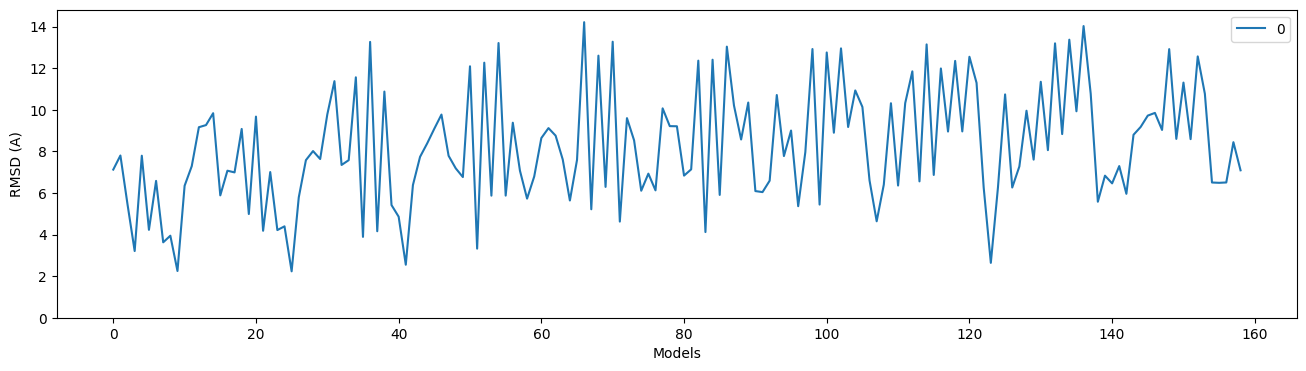

In [ ]:
# Plot the distance (RMSD) per model compared with the first model
df_ = pd.DataFrame(distance_list)
ax = df_.plot(figsize=(16,4))
ax.set_xlabel("Models")
ax.set_ylabel("RMSD (A)")
ax.set_ylim(0)

#### Residue distance distribution
Calculate distance across models at the residue level

In [ ]:
# Swap axes
coords_array = np.array(coords_list)
coords_array = np.swapaxes(coords_array, 0, 1)
coords_array.shape

(148, 160, 3)

In [ ]:
# Calculate RSD at the residue level (all Vs first model)
res_distance = []

# Iterate residues
for i in range(coords_array.shape[0]):
  distance = []

  # Iterate models
  for j in range(1, coords_array.shape[1]):
    distance.append(np.sum(coords_array[i][0] - coords_array[i][j])**2)
  res_distance.append(np.sqrt(np.array(distance)))#/coords_array.shape[1]))

# residues x models x coords
res_distance = np.array(res_distance)
print(res_distance.shape)

(148, 159)


Text(0, 0.5, 'Distance (A)')

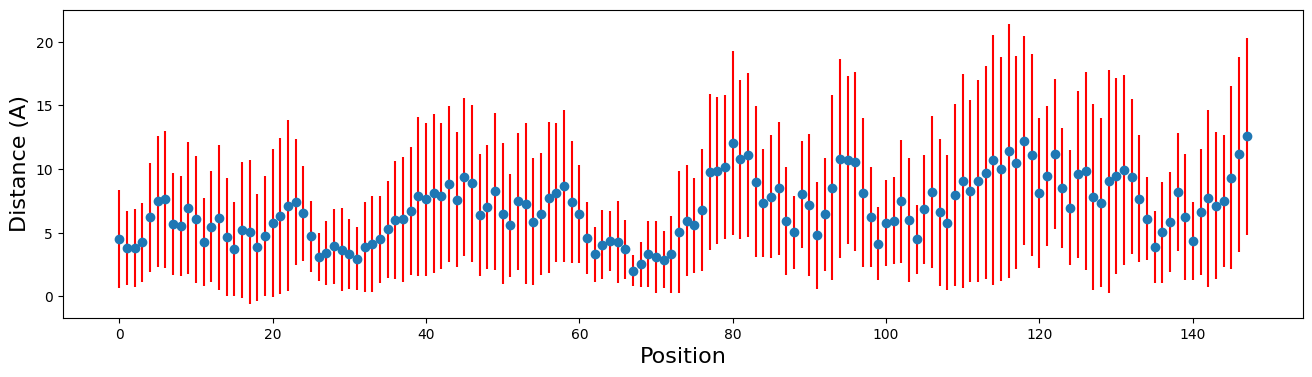

In [ ]:
mean = res_distance.mean(axis=1)
std = res_distance.std(axis=1)

plt.figure(figsize=(16,4))
plt.errorbar(range(len(mean)), mean, yerr= std, ecolor='red', fmt = 'o')
plt.xlabel("Position", fontsize=16)
plt.ylabel('Distance (A)', fontsize=16)